# EWELD C24 — Benchmark a lungo termine (30–90 giorni)

Previsione **giornaliera** dei consumi (kWh/giorno) a **90 giorni** dall'origine, valutata ai tagli di 30, 60 e 90 giorni.
Il codice sta nelle librerie accanto al notebook:

| File | Ruolo |
|---|---|
| `dati.py` | serie giornaliera, pulizia, origini di validazione e test, scala MASE |
| `modelli.py` | registro dei modelli: baseline, statistici, alberi, preaddestrati zero-shot, reti globali |
| `../metriche.py` | MAE, RMSE, MAPE, sMAPE, MASE, Bias, errore totale %, copertura e larghezza dell'intervallo 80%, test di Diebold-Mariano (file unico per tutti i benchmark, nella radice) |
| `esperimento.py` | `esegui`: addestra, prevede, calcola le metriche e salva i risultati in `risultati/` |

Divisione per date: **train** fino al 2018-09-30; **validazione** con origini dal 2018-10-01 al 2019-01-01 (mensili);
**test** con origini dal 2019-04-01 al 2020-05-01 (14 origini mensili), dopo il riaddestramento fino al 2019-03-31.
Si valutano solo le origini i cui 90 giorni di target sono tutti validi.

In [1]:
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append(str(Path.cwd().parent))   # metriche.py, unico per tutti i benchmark, sta nella radice
import dati
import metriche
import modelli
from esperimento import esegui

UTENTE = 'U141'
TUTTI = modelli.MODELLI
N_ALBERI = [50, 100, 300, 600]
SALTA_PATCHTST_MULTI = False     # True: esclude PatchTST dalla sezione 4 per contenere i tempi
print(TUTTI)

['Naive settimanale', 'Profilo 8 settimane', 'Anno precedente', 'STL+ETS', 'ETS', 'SARIMA', 'Regressione Fourier', 'LightGBM', 'XGBoost', 'Chronos-2', 'Chronos-Bolt', 'TimesFM 2.5', 'TimesFM 3.0', 'Timestral 209M', 'N-HiTS', 'PatchTST']


## 1. Dati e pulizia di U141

La serie oraria viene pulita e aggregata a giorni; i tratti piatti (fermi, dati mancanti) diventano NaN e le origini con un target non valido sono **scartate**.

U141: 1261 giorni validi su 1552 | scala MASE (lag 7 sul train) = 18583.7 kWh
Origini valide: {'validazione': 4, 'test': 14}
Origini scartate: {'validazione': [], 'test': []}


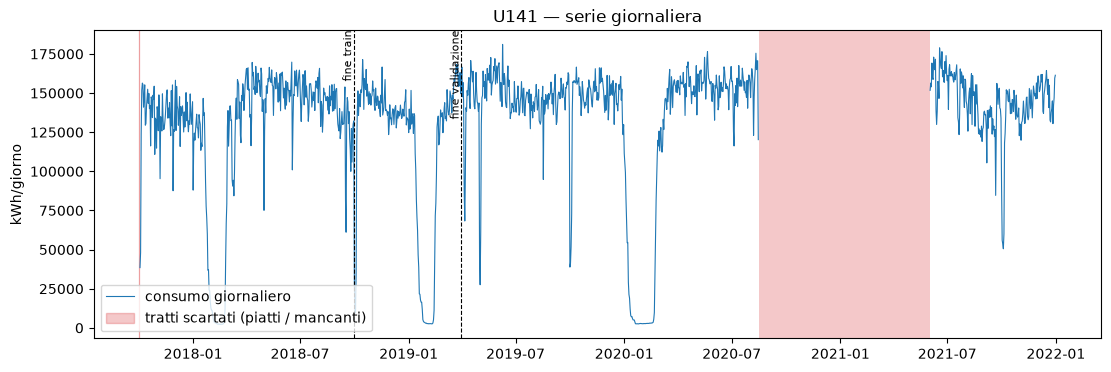

In [2]:
D = dati.prepara_dati(UTENTE)
print(f'{D.utente}: {D.serie.notna().sum()} giorni validi su {len(D.serie)} | scala MASE (lag 7 sul train) = {D.scala_mase:.1f} kWh')
print('Origini valide:', {f: len(o) for f, o in D.origini.items()})
print('Origini scartate:', {f: [f'{o:%Y-%m-%d}' for o in s] for f, s in D.scartate.items()})

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(D.serie.index, D.serie.values, lw=0.8, label='consumo giornaliero')
nan = D.serie.isna()
inizio = None
for giorno, mancante in nan.items():
    if mancante and inizio is None:
        inizio = giorno
    if not mancante and inizio is not None:
        ax.axvspan(inizio, giorno, color='tab:red', alpha=0.25, lw=0)
        inizio = None
if inizio is not None:
    ax.axvspan(inizio, nan.index[-1], color='tab:red', alpha=0.25, lw=0)
ax.axvspan(D.serie.index[0], D.serie.index[0], color='tab:red', alpha=0.25, label='tratti scartati (piatti / mancanti)')
for data, nome in [(dati.FINE_TRAIN, 'fine train'), (dati.FINE_VALIDAZIONE, 'fine validazione')]:
    ax.axvline(pd.Timestamp(data), color='k', ls='--', lw=0.8)
    ax.text(pd.Timestamp(data), ax.get_ylim()[1], nome, rotation=90, va='top', ha='right', fontsize=8)
ax.set_ylabel('kWh/giorno'); ax.set_title(f'{UTENTE} — serie giornaliera'); ax.legend(loc='lower left')
plt.show()

## 2. Validazione su U141 e scelta degli iperparametri

Tutti i modelli sono addestrati fino al 2018-09-30 e valutati sulle origini di validazione.
Per **LightGBM** e **XGBoost** il numero di alberi viene scelto confrontando 50, 100, 300 e 600 alberi sul MAE al taglio 90.

**N-HiTS** e **PatchTST** usano gli iperparametri di default di neuralforecast (contesto 365 giorni, 1000 passi al più, learning rate 1e-3, scaler robusto), senza ricerca:
ogni addestramento globale su 11 utenze costa minuti (PatchTST oltre dieci) e una griglia moltiplicherebbe il costo per ogni combinazione.
L'unica scelta fatta sui dati è **quale epoca tenere**: ogni 50 epoche si misura il MAE della mediana (kWh/giorno)
su 4 finestre di train per serie e sugli ultimi 90 giorni di ogni serie (validazione, sempre prima di `fino_a`),
e si conservano i pesi dell'epoca con il MAE di validazione minimo, non quelli dell'ultima.
Le curve MAE per epoca sono mostrate nella sezione 3.6, come i grafici di addestramento di `c24_benchmark`.


In [3]:
val = esegui([UTENTE], TUTTI, fase='validazione')
print('Cartella:', val['cartella']); print('Errori:', len(val['errori']))
metriche.formatta(val['metriche'].loc[UTENTE])

Cartella: /Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/lungo_termine_benchmark/risultati/U141_20261113_090403
Errori: 0


In [4]:
confronto = {}
with tempfile.TemporaryDirectory() as tmp:
    for nome in ['LightGBM', 'XGBoost']:
        for n in N_ALBERI:
            r = esegui([UTENTE], [nome], fase='validazione', parametri={nome: {'n_estimators': n}}, cartella=Path(tmp)/f'{nome}_{n}')
            confronto[(nome, n)] = r['metriche'].loc[(UTENTE, nome, 90), ['MAE', 'MASE']]
confronto = pd.DataFrame(confronto).T.rename_axis(['modello', 'n_estimators'])
SCELTI = {nome: int(confronto.loc[nome]['MAE'].idxmin()) for nome in ['LightGBM', 'XGBoost']}
PARAMETRI = {nome: {'n_estimators': n} for nome, n in SCELTI.items()}
print('Alberi scelti (MAE a 90 giorni sulla validazione):', SCELTI)
confronto

Alberi scelti (MAE a 90 giorni sulla validazione): {'LightGBM': 100, 'XGBoost': 100}


MAE      MASE
modello  n_estimators                        
LightGBM 50            27558.466132  1.482938
         100           23769.694374  1.279062
         300           24296.221055  1.307395
         600           23948.323963  1.288674
XGBoost  50            29188.345776  1.570643
         100           20792.392578  1.118852
         300           23259.072762  1.251585
         600           22900.135493  1.232271

## 3. Test su U141

Riaddestramento fino al 2019-03-31 e previsione dalle 14 origini di test (quelle valide), con gli alberi scelti in sezione 2.

In [5]:
test = esegui([UTENTE], TUTTI, fase='test', parametri=PARAMETRI)
print('Cartella:', test['cartella']); print('Errori:', len(test['errori']))
print('Secondi per modello:', {k: round(v) for k, v in test['secondi'].items()})
T = test['metriche'].loc[UTENTE]
pd.Series(metriche.descrizione('kWh/giorno', 'naive settimanale (lag 7)'), name='significato').to_frame()

Cartella: /Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/lungo_termine_benchmark/risultati/U141_20261113_091430
Errori: 0
Secondi per modello: {'Naive settimanale': 0, 'Profilo 8 settimane': 0, 'Anno precedente': 0, 'STL+ETS': 0, 'ETS': 0, 'SARIMA': 5, 'Regressione Fourier': 0, 'LightGBM': 2, 'XGBoost': 2, 'Chronos-2': 7, 'Chronos-Bolt': 5, 'TimesFM 2.5': 6, 'TimesFM 3.0': 3, 'Timestral 209M': 6, 'N-HiTS': 46, 'PatchTST': 747}


,significato
MAE,errore assoluto medio (kWh/giorno)
RMSE,radice dell’errore quadratico medio (kWh/giorno)
MAPE %,errore percentuale assoluto medio sui valori r...
sMAPE %,errore percentuale simmetrico
MASE,MAE / MAE del naive settimanale (lag 7) sul tr...
Bias,media di (previsto − reale): >0 sovrastima (kW...
Errore totale %,errore % sul consumo cumulato di ogni finestra...
Copertura 80%,% di valori reali dentro l’intervallo q10–q90 ...
Larghezza 80%,ampiezza media dell’intervallo q10–q90 (kWh/gi...


### 3.1 Taglio 30 giorni

In [6]:
metriche.formatta(T.xs(30, level='taglio'))

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
Naive settimanale,23457.0,42884.0,207.14,25.66,1.262,+5377.5,46.89,nan,nan
Profilo 8 settimane,36630.9,57038.0,346.04,42.90,1.971,-2707.3,61.09,nan,nan
Anno precedente,26671.5,38554.2,62.68,32.82,1.435,-2556.3,27.52,nan,nan
STL+ETS,20967.2,39042.5,194.00,24.26,1.128,+7546.8,42.91,88.57,110812.5
ETS,19934.7,37524.0,189.53,25.06,1.073,+5087.4,40.40,89.76,130710.0
SARIMA,24674.7,38312.3,250.42,30.39,1.328,+468.0,42.51,89.29,110195.1
Regressione Fourier,21205.9,32003.6,150.83,28.30,1.141,+13987.0,26.26,81.19,59806.1
LightGBM,19730.7,27236.5,123.60,27.97,1.062,+2075.1,18.71,nan,nan
XGBoost,20337.5,27177.9,92.19,25.85,1.094,+58.3,13.42,nan,nan


### 3.2 Taglio 60 giorni

In [7]:
metriche.formatta(T.xs(60, level='taglio'))

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
Naive settimanale,31586.4,55222.2,328.58,35.24,1.700,+5052.8,49.93,nan,nan
Profilo 8 settimane,41161.2,62810.6,406.10,45.18,2.215,-3076.9,52.03,nan,nan
Anno precedente,30104.0,44835.8,88.25,34.85,1.620,-4553.0,30.54,nan,nan
STL+ETS,28483.6,51619.2,309.28,33.29,1.533,+7141.2,45.81,84.64,154438.4
ETS,28028.0,50732.0,304.22,33.76,1.508,+4700.5,44.01,86.31,181204.8
SARIMA,30681.6,44552.7,325.40,33.95,1.651,-1794.5,41.63,87.98,124704.3
Regressione Fourier,19702.1,31206.8,154.68,27.29,1.060,+12256.5,21.21,84.40,59782.9
LightGBM,20694.4,29813.6,133.15,29.02,1.114,+370.2,17.01,nan,nan
XGBoost,22464.5,32395.1,120.75,28.60,1.209,+266.1,19.26,nan,nan


### 3.3 Taglio 90 giorni

In [8]:
metriche.formatta(T.xs(90, level='taglio'))

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
Naive settimanale,34760.0,59401.9,375.07,38.57,1.870,+4913.7,31.78,nan,nan
Profilo 8 settimane,42588.6,64632.7,427.45,45.91,2.292,-3251.3,34.35,nan,nan
Anno precedente,31176.1,46957.5,95.33,35.43,1.678,-5652.8,22.89,nan,nan
STL+ETS,31516.8,56171.6,357.52,36.40,1.696,+6967.7,28.91,85.16,187896.5
ETS,31579.8,56189.2,358.54,36.85,1.699,+4549.5,28.98,89.92,217091.6
SARIMA,33043.9,46766.2,355.31,35.32,1.778,-2875.5,26.31,87.86,130808.1
Regressione Fourier,18799.5,30492.3,157.57,26.68,1.012,+11199.6,14.02,85.63,59785.0
LightGBM,21818.4,32922.1,153.49,29.78,1.174,-93.3,12.79,nan,nan
XGBoost,23075.0,35226.9,145.04,29.28,1.242,+153.5,15.29,nan,nan


### 3.4 MAE per orizzonte

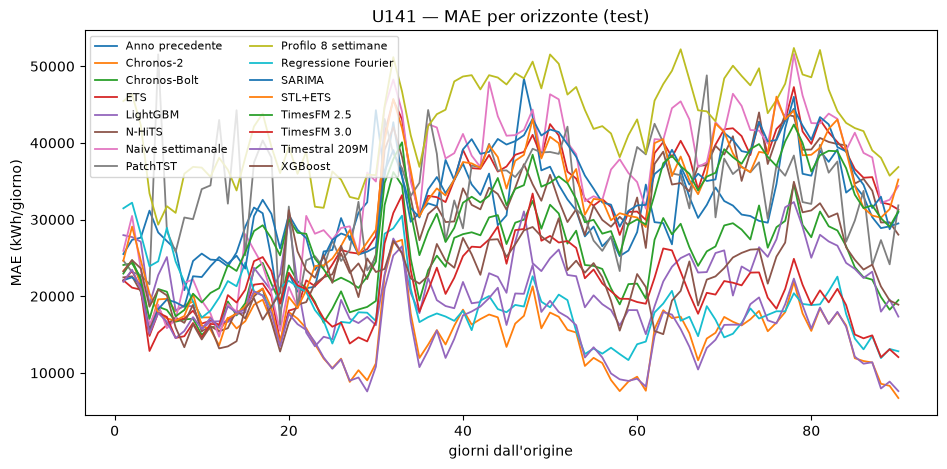

In [9]:
P = test['previsioni']
fig, ax = plt.subplots(figsize=(11, 5))
for nome, g in P.groupby('modello'):
    reale = g['reale'].to_numpy().reshape(-1, dati.HORIZON)
    punto = g['punto'].to_numpy().reshape(-1, dati.HORIZON)
    ax.plot(range(1, dati.HORIZON+1), metriche.mae_per_orizzonte(reale, punto), label=nome, lw=1.3)
ax.set_xlabel('giorni dall\'origine'); ax.set_ylabel('MAE (kWh/giorno)'); ax.set_title(f'{UTENTE} — MAE per orizzonte (test)')
ax.legend(ncol=2, fontsize=8); plt.show()

### 3.5 Finestre con il fermo 2020

Solo le origini da 2019-11-01 a 2020-02-01, le cui finestre a 90 giorni contengono il fermo del 2020 (se valide).

In [10]:
fermo = test['metriche_fermo']
if fermo is None:
    print('Nessuna origine valida nel periodo del fermo.')
else:
    display(metriche.formatta(fermo.loc[UTENTE].xs(90, level='taglio')))

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
Naive settimanale,80531.9,102940.4,1276.54,103.74,4.333,+22757.2,94.33,nan,nan
Profilo 8 settimane,71448.3,90572.2,1437.34,87.91,3.845,+43303.8,79.52,nan,nan
Anno precedente,44033.6,63295.9,285.39,70.23,2.369,-1016.2,45.19,nan,nan
STL+ETS,78109.1,99857.0,1220.73,103.95,4.203,+18563.0,88.21,53.06,173202.6
ETS,77804.6,99852.3,1224.73,104.84,4.187,+20516.9,88.98,68.61,200968.7
SARIMA,58166.4,75840.8,1198.60,81.00,3.130,+35393.5,61.71,63.06,117834.7
Regressione Fourier,28340.3,44773.5,517.63,66.68,1.525,+25800.8,33.52,71.11,55243.3
LightGBM,37021.6,50460.9,504.18,75.17,1.992,+6130.5,33.66,nan,nan
XGBoost,37398.2,53787.4,474.54,71.70,2.012,+5773.1,36.51,nan,nan


### 3.6 Test di Diebold-Mariano contro il naive settimanale

Per ogni modello e taglio: perdita = MAE di ciascuna origine, statistica con la correzione di Harvey-Leybourne-Newbold
e t di Student a n−1 gradi. Le finestre di origini mensili si sovrappongono, quindi le perdite sono autocorrelate fino al
ritardo h−1 con h = ⌈taglio/30⌉. **DM < 0** vuol dire che il modello sbaglia meno del naive; con 14 origini il test ha poca
potenza, quindi un p alto non vuol dire che i modelli si equivalgono.

In [11]:
dm = test['dm'].loc[UTENTE]
dm.unstack('taglio').style.format({c: '{:.3f}' for c in dm.unstack('taglio').columns if c[0] == 'p'} |
                                  {c: '{:+.2f}' for c in dm.unstack('taglio').columns if c[0] == 'DM'})

### 3.7 Curve di addestramento delle reti

MAE (kWh/giorno) di train e di validazione per epoca di N-HiTS e PatchTST nell'addestramento del test (fino al 2019-03-31),
nello stesso formato dei grafici di `c24_benchmark`. Con 11 serie ogni epoca è un solo passo di ottimizzazione.
La linea tratteggiata indica l'epoca i cui pesi sono stati conservati (MAE di validazione minimo).


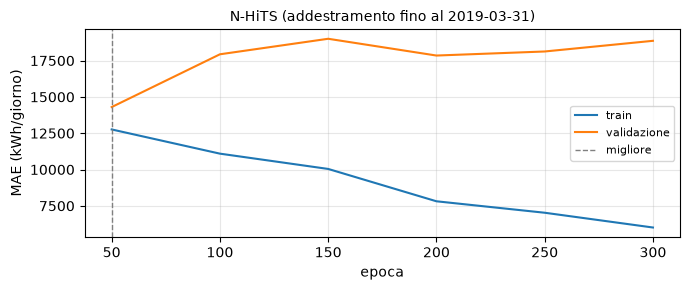

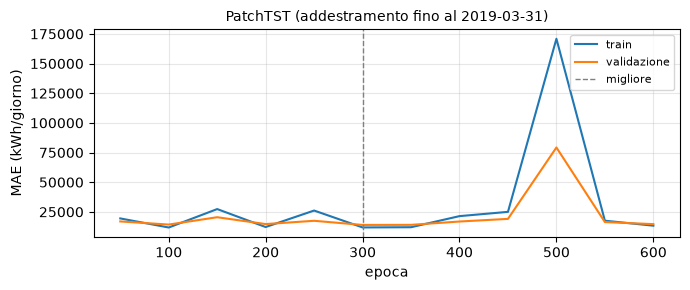

,epoca tenuta,MAE validazione tenuta,epoche eseguite,quantili incrociati U141
N-HiTS,50.0,14300.563477,300.0,0.017460
PatchTST,300.0,13981.791016,600.0,0.053968


In [12]:
reti_addestrate = [nome for nome in ['N-HiTS', 'PatchTST'] if test['storia'].get(nome, {}).get('globale')]
for nome in reti_addestrate:
    s = test['storia'][nome]['globale']
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(s['epoche'], s['train'], label='train', lw=1.5)
    ax.plot(s['epoche'], s['validazione'], label='validazione', lw=1.5)
    ax.axvline(s['epoca_migliore'], color='grey', ls='--', lw=1, label='migliore')
    ax.set_title(f'{nome} (addestramento fino al 2019-03-31)', fontsize=10)
    ax.set_xlabel(s['unita']); ax.set_ylabel('MAE (kWh/giorno)')
    ax.grid(alpha=.3); ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
pd.DataFrame({nome: {'epoca tenuta': test['storia'][nome]['globale']['epoca_migliore'],
                     'MAE validazione tenuta': test['storia'][nome]['globale']['mae_val_migliore'],
                     'epoche eseguite': test['storia'][nome]['globale']['passo_finale'],
                     f'quantili incrociati {UTENTE}': test['storia'][nome]['globale']['quantili_incrociati'][UTENTE]}
              for nome in reti_addestrate}).T


**Lettura delle curve.** Se il MAE di train scende mentre quello di validazione sale, la rete sta sovradattando: si tengono i pesi
dell'epoca con il MAE di validazione minimo. La validazione è sugli ultimi 90 giorni di ogni serie, quindi su un solo trimestre
(gennaio–marzo 2019, con il fermo del Capodanno lunare): l'epoca scelta è rumorosa e le reti con i default restano poco addestrate.
Il MAE delle curve è aggregato su tutte le 11 utenze, quindi pesano di più quelle con i consumi maggiori.


## 4. Multi-utente

Test su tutte le utenze idonee (`dati.utenze_idonee()`). I modelli globali sono addestrati una volta sola su tutte le idonee.

In [13]:
IDONEE = dati.utenze_idonee()
modelli_multi = [m for m in TUTTI if not (SALTA_PATCHTST_MULTI and m == 'PatchTST')]
multi = esegui(IDONEE, modelli_multi, fase='test', parametri=PARAMETRI)
print(len(IDONEE), 'utenze | cartella:', multi['cartella']); print('Errori:', len(multi['errori']))
print('Secondi per modello:', {k: round(v) for k, v in multi['secondi'].items()})
multi['errori']

11 utenze | cartella: /Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/lungo_termine_benchmark/risultati/multi_20261113_092821
Errori: 0
Secondi per modello: {'Naive settimanale': 0, 'Profilo 8 settimane': 0, 'Anno precedente': 0, 'STL+ETS': 1, 'ETS': 2, 'SARIMA': 53, 'Regressione Fourier': 9, 'LightGBM': 56, 'XGBoost': 32, 'Chronos-2': 72, 'Chronos-Bolt': 86, 'TimesFM 2.5': 89, 'TimesFM 3.0': 15, 'Timestral 209M': 20, 'N-HiTS': 75, 'PatchTST': 776}


,utente,modello,errore


### 4.1 Media per modello (taglio 90 e 30)

In [14]:
M_ = multi['metriche']
media = M_.groupby(['modello', 'taglio']).mean()
for t in (30, 90):
    display(metriche.formatta(media.xs(t, level='taglio').sort_values('MASE')))

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
Timestral 209M,4668.1,7829.0,187.70,26.62,0.960,+1332.8,48.54,80.54,14363.8
Chronos-2,4732.1,8071.1,175.41,27.96,0.973,+1636.3,46.73,75.05,12969.1
TimesFM 3.0,4957.7,8268.8,204.61,28.08,1.021,+1493.1,54.05,77.69,14003.5
Chronos-Bolt,5093.9,8909.9,212.09,28.83,1.033,+2002.6,36.79,77.65,14940.8
TimesFM 2.5,5477.4,9291.8,216.14,28.34,1.042,+1859.2,47.02,77.55,14218.4
STL+ETS,5972.0,9575.0,170.88,33.36,1.190,+674.0,26.34,88.52,33244.3
Naive settimanale,6229.8,10150.7,190.13,31.64,1.200,+537.1,25.56,nan,nan
ETS,5841.8,9438.6,159.82,34.86,1.230,+299.0,26.97,90.66,38163.1
N-HiTS,5925.4,9163.2,144.52,37.74,1.290,+354.2,28.78,68.96,17207.4


,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
Timestral 209M,5030.7,8053.8,206.57,28.32,1.084,+1227.1,15.17,82.27,18334.7
Chronos-2,5092.5,8279.5,194.26,28.92,1.088,+1563.8,15.15,76.53,15968.3
TimesFM 3.0,5753.9,9313.2,225.67,30.48,1.193,+1430.4,17.28,76.99,18255.1
Chronos-Bolt,5921.3,9920.7,285.41,31.71,1.251,+2248.2,20.66,74.71,17834.9
TimesFM 2.5,6631.2,10590.7,270.87,31.42,1.276,+1883.0,20.14,75.56,17972.4
SARIMA,7441.5,10068.1,282.91,35.32,1.469,-1572.5,22.44,83.24,33170.4
Regressione Fourier,6728.6,9906.2,213.59,33.97,1.470,+3264.6,21.76,78.84,19432.6
STL+ETS,7634.3,11863.1,259.73,40.08,1.519,+626.1,26.74,93.02,54875.9
ETS,7572.8,11725.4,242.89,41.48,1.544,+237.5,26.81,94.94,60831.3


### 4.2 Classifica per utenza (MASE a 90 giorni)

In [15]:
mase = M_.xs(90, level='taglio')['MASE'].unstack('modello')
classifica = mase.rank(axis=1)
display(mase.style.format('{:.2f}').highlight_min(axis=1, props='font-weight:bold'))
pd.DataFrame({'rango medio': classifica.mean().sort_values(), 'vittorie': (classifica == 1).sum()}).sort_values('rango medio')

modello,Anno precedente,Chronos-2,Chronos-Bolt,ETS,LightGBM,N-HiTS,Naive settimanale,PatchTST,Profilo 8 settimane,Regressione Fourier,SARIMA,STL+ETS,TimesFM 2.5,TimesFM 3.0,Timestral 209M,XGBoost
utente,,,,,,,,,,,,,,,,
U135,2.17,1.26,1.57,2.06,1.59,2.05,2.04,1.91,2.18,1.54,2.23,1.87,1.57,1.42,1.30,1.58
U137,0.82,0.65,0.68,0.84,0.84,0.96,0.88,1.43,0.71,0.81,0.74,0.87,0.64,0.65,0.64,0.80
U138,1.48,0.84,0.84,0.90,1.37,1.11,1.14,1.18,1.19,1.21,1.41,1.14,0.85,0.90,0.88,2.08
U141,1.68,0.84,1.31,1.70,1.17,1.59,1.87,1.79,2.29,1.01,1.78,1.70,1.64,1.14,0.85,1.24
U142,1.42,1.01,1.37,1.63,1.22,1.51,1.66,1.56,1.85,0.90,1.52,1.69,1.24,0.99,0.92,1.26
U143,1.42,0.95,0.94,1.22,1.73,1.31,1.31,1.09,1.30,1.28,1.06,1.20,0.91,1.15,0.96,1.77
U144,1.15,0.79,0.89,1.27,0.83,1.35,1.23,1.12,1.14,1.02,0.93,1.20,0.85,0.70,0.71,0.88
U147,1.82,0.94,0.93,1.21,2.18,1.24,1.23,1.28,1.74,1.18,1.40,1.24,1.00,0.97,0.93,1.64
U148,2.64,2.26,2.92,3.19,2.90,3.34,2.72,2.86,2.76,3.37,2.82,2.89,2.77,2.71,2.39,2.99


,rango medio,vittorie
modello,,
Timestral 209M,2.272727,2
Chronos-2,2.727273,3
TimesFM 3.0,3.909091,1
TimesFM 2.5,5.000000,1
Chronos-Bolt,5.090909,2
Regressione Fourier,8.363636,1
SARIMA,8.818182,1
LightGBM,10.363636,0
XGBoost,10.545455,0


### 4.3 Diebold-Mariano per utenza

Su quante utenze ogni modello batte il naive settimanale (DM < 0) o ne è battuto (DM > 0) con p < 0.05, per taglio.
Le utenze non sono indipendenti tra loro (stesso settore, stessi fermi), quindi i conteggi non vanno sommati in un unico test.

In [16]:
DM_ = multi['dm']
significativi = DM_['p'] < 0.05
conteggi = pd.DataFrame({'batte il naive': (significativi & (DM_['DM'] < 0)).groupby(['modello', 'taglio']).sum(),
                         'battuto dal naive': (significativi & (DM_['DM'] > 0)).groupby(['modello', 'taglio']).sum(),
                         'utenze': DM_['DM'].notna().groupby(['modello', 'taglio']).sum()})
conteggi.unstack('taglio')

batte il naive       battuto dal naive       utenze      \
taglio                          30 60 90                30 60 90     30  60   
modello                                                                       
Anno precedente                  0  0  0                 1  0  0     11  10   
Chronos-2                        2  3  2                 0  0  0     11  11   
Chronos-Bolt                     1  3  2                 0  0  0     11  11   
ETS                              0  1  0                 2  1  0     11  11   
LightGBM                         0  0  0                 0  0  0     11  11   
N-HiTS                           0  0  0                 2  0  0     11  10   
PatchTST                         0  0  0                 1  1  1     11  11   
Profilo 8 settimane              1  1  1                 0  0  0     11  10   
Regressione Fourier              0  1  1                 0  1  0     11  11   
SARIMA                           1  1  2                 1  0  1     11  11   
STL+ETS                          0  0  0                 0  1  0     11  11   
TimesFM 2.5                      3  4  3                 0  0  0     11  11   
TimesFM 3.0                      3  3  3                 0  0  0     11  11   
Timestral 209M                   3  3  3                 0  0  0     11  11   
XGBoost                          0  0  0                 0  1  0     11  11   

                         
taglio               90  
modello                  
Anno precedente      10  
Chronos-2            11  
Chronos-Bolt         10  
ETS                  10  
LightGBM             10  
N-HiTS               10  
PatchTST             10  
Profilo 8 settimane   8  
Regressione Fourier  11  
SARIMA               10  
STL+ETS              11  
TimesFM 2.5          10  
TimesFM 3.0          10  
Timestral 209M        9  
XGBoost              11

### 4.4 Note sui risultati

- **Preaddestrati in testa.** Chronos-2 (MASE medio a 90 giorni 1.09, rango medio 2.0) e TimesFM 3.0 (1.19) sono i migliori anche sulle 11 utenze; seguono Chronos-Bolt e TimesFM 2.5 (1.25–1.28).
- **Regressione Fourier.** Escludere dall'addestramento le origini a livello di fermo (sotto 0.6 volte la mediana dei livelli) e usare la mediana in previsione quando il livello è di fermo
  la porta da MASE 4.62 a 1.01 su U141 (seconda dopo Chronos-2) e da 3.68 a 1.47 in media: è il miglior modello non preaddestrato.
  Resta fragile dove i fermi sono lunghi o il livello cambia molto: U148 (3.37; 420 origini di addestramento scartate su 942) e U155 (2.90).
- **Reti.** Con i pesi dell'epoca migliore PatchTST passa da 9.34 a 1.48 di MASE medio (rango medio 7.8, davanti a statistici e alberi) e N-HiTS da 1.80 a 1.59 (ultimo per rango medio).
  Il confronto con gli altri modelli è comunque prudente: iperparametri di default, un solo seed, scelta dell'epoca su un trimestre di validazione e loss di addestramento instabile
  (sezione 3.6). Su U141 entrambe restano peggiori degli alberi (1.59 e 1.62 contro 1.17 di LightGBM). La copertura dell'80% di N-HiTS è bassa (66% in media).
- **Quantili incrociati.** Il punto delle reti è la mediana di MQLoss senza riordinamento; la quota di punti con mediana fuori da [q10, q90] è sotto il 2% per N-HiTS
  e fino all'11% per PatchTST (U144), dove q10/q90 sono allargati fino alla mediana.